In [3]:
import h5py
import pylab as plt
import numpy as np
from matplotlib.dates import num2date
from datetime import datetime
import pytz
import matplotlib.ticker as ticker

# Load Samples Data

In [4]:
hdf_samples = h5py.File('../data/validation/unsignedflux_samples.h5')
print(hdf_samples.keys())
#lat_extent_samples = hdf_samples['lat_extent'][:].squeeze()
unsigned_flux_samples = hdf_samples['unsigned_flux'][:].squeeze()
times_d2n = hdf_samples['times_d2n'][:]
hdf_samples.close()

<KeysViewHDF5 ['contexts', 'rs', 'times_d2n', 'unsigned_flux']>


In [5]:
unsigned_flux_samples.shape

(2748, 4)

In [6]:
times_samples = np.array(num2date(times_d2n))

In [7]:
unsigned_flux_samples

array([[322775.33289133,   8603.57474454,   4367.98244939,
          3056.91666059],
       [260699.679114  ,   4422.96845211,   1624.36129412,
           911.23689078],
       [126976.26000037,   2306.35203676,   1170.44485592,
           802.60464066],
       ...,
       [289567.35700723,   5027.88464496,   1947.38716346,
          1106.10079733],
       [136279.2587767 ,   2759.00947624,   1320.61216609,
           919.04651009],
       [ 99415.71929454,   2071.47672336,   1219.05855771,
           947.62233082]], shape=(2748, 4))

# Load Training Data

In [8]:
hdf_testdata = h5py.File('../data/validation/unsignedflux_testdata.h5')
unsigned_flux_testdata = hdf_testdata['unsigned_flux'][:].squeeze()
times_d2n = hdf_testdata['times_d2n'][:]
times_testdata = np.array(num2date(times_d2n))
hdf_testdata.close()

In [9]:
unsigned_flux_testdata.shape

(5496, 4)

In [10]:
unsigned_flux_testdata

array([[216456.79333159,   3629.66238376,   1672.83863725,
          1183.56230839],
       [216456.79333159,   3629.66238376,   1672.83863725,
          1183.56230839],
       [201867.45917809,   3311.66730526,   1402.7176217 ,
           929.83709949],
       ...,
       [184881.76224856,   3220.17892505,   1653.45394569,
          1178.93826743],
       [182210.1354656 ,   3258.30523287,   1670.68684183,
          1188.05418584],
       [182210.1354656 ,   3258.30523287,   1670.68684183,
          1188.05418584]], shape=(5496, 4))

# Plot Experiment

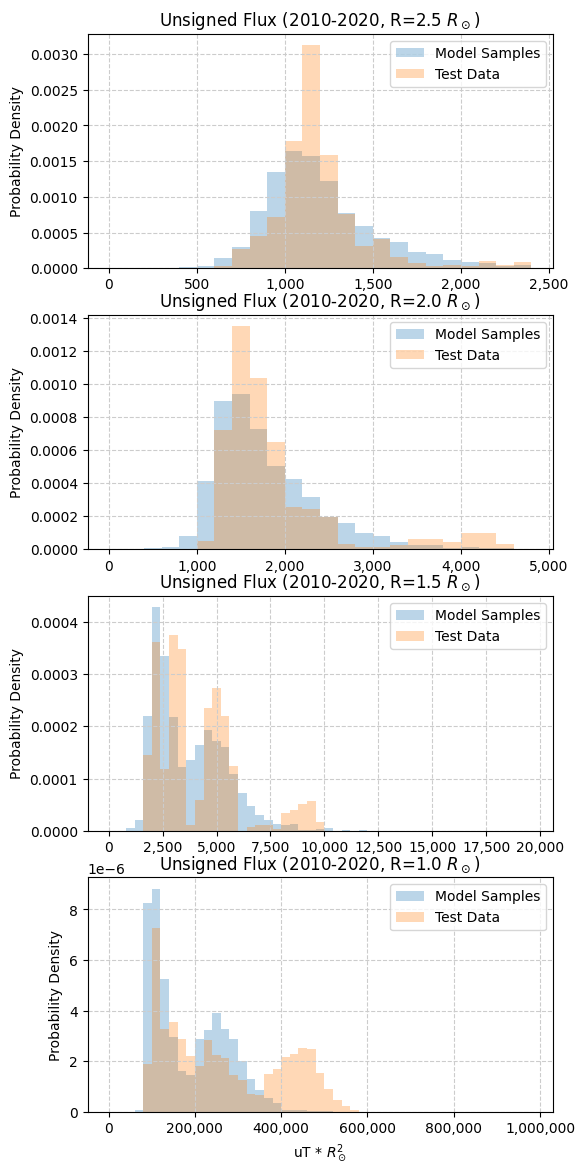

In [15]:
#bins = np.arange(0, 50000, 1000)

bins = [
    np.arange(0, 1_000_000, 20000),  
    np.arange(0, 1_000_000, 20000) / 50, 
    np.arange(0, 500_000, 20000) / 100, 
    np.arange(0, 500_000, 20000) / 200, 

]
radii = [1.0, 1.5, 2.0, 2.5]

cutoff = datetime(2021, 1, 1).replace(tzinfo=pytz.utc)  
mask1 = times_samples < cutoff
mask2 = times_testdata < cutoff

fig, axes = plt.subplots(4, 1, figsize=(6, 14))

for i in range(4):
    ax = axes[len(axes) - 1 - i]
        
    ax.set_title(rf'Unsigned Flux (2010-2020, R={radii[i]} $R_\odot$)')
    ax.hist(unsigned_flux_samples[mask1, i], label='Model Samples', bins=bins[i], alpha=0.3, density=True)
    ax.hist(unsigned_flux_testdata[mask2, i], bins=bins[i],  label='Test Data', alpha=0.3, density=True)
    
    ax.legend()
    ax.set_ylabel('Probability Density')
    if i == 0: ax.set_xlabel(r'uT * $R_\odot^2$')
    ax.grid(linestyle='dashed', color='#ccc')
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

fig.savefig('../plots/paper/unsignedflux.png', dpi=300, bbox_inches='tight')

In [14]:

for i in range(4):
    print(f"Layer {i}")
    print("="*40)
    print('Samples')
    print('---------')
    print(f'Mean {np.mean(unsigned_flux_samples[mask1,i]):,.1f}')
    print(f'STD {np.std(unsigned_flux_samples[mask1,i]):,.1f}')
    print()
    print('Test Dataset')
    print('---------')
    print(f'Mean {np.mean(unsigned_flux_testdata[mask2,i]):,.1f}')
    print(f'STD {np.std(unsigned_flux_testdata[mask2,i]):,.1f}')
    print()

Layer 0
Samples
---------
Mean 185,808.0
STD 84,737.7

Test Dataset
---------
Mean 265,196.0
STD 136,737.4

Layer 1
Samples
---------
Mean 3,715.5
STD 1,611.2

Test Dataset
---------
Mean 4,131.5
STD 1,889.2

Layer 2
Samples
---------
Mean 1,783.8
STD 596.4

Test Dataset
---------
Mean 1,898.5
STD 714.9

Layer 3
Samples
---------
Mean 1,220.1
STD 356.5

Test Dataset
---------
Mean 1,277.1
STD 418.9

